<a href="https://colab.research.google.com/github/phamquocan14102006/ThucHanhHocMay-2045240006/blob/main/PhamQuocAn_BTVN_Tuan2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#btolop1
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Tải dữ liệu phân lớp mẫu (Iris) và chia tập huấn luyện / kiểm tra
X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# So sánh trước và sau chuẩn hóa với K = 5
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)
acc_raw = accuracy_score(y_test, knn_raw.predict(X_test))

pipe_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])
pipe_scaled.fit(X_train, y_train)
acc_scaled = accuracy_score(y_test, pipe_scaled.predict(X_test))

print(f"Accuracy chưa chuẩn hóa (K=5, Euclidean): {acc_raw:.4f}")
print(f"Accuracy có StandardScaler (K=5, Euclidean): {acc_scaled:.4f}\n")

# 2. Thực nghiệm với các giá trị K và độ đo khoảng cách (Manhattan, Minkowski)
k_values = [1, 3, 5, 7, 9, 11]
metrics = [
    {"name": "Manhattan", "metric": "manhattan", "p": None},
    {"name": "Minkowski (p=3)", "metric": "minkowski", "p": 3},
]

best_combo = None
best_acc = -1.0

for item in metrics:
    print(f"=== Độ đo khoảng cách: {item['name']} ===")
    for k in k_values:
        kwargs = {"n_neighbors": k, "metric": item["metric"]}
        if item["p"] is not None:
            kwargs["p"] = item["p"]

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("knn", KNeighborsClassifier(**kwargs))
        ])
        model.fit(X_train, y_train)
        acc = accuracy_score(y_test, model.predict(X_test))
        print(f"  K = {k:2d} | Accuracy = {acc:.4f}")

        if acc > best_acc:
            best_acc = acc
            best_combo = (item["name"], k, acc)

print(
    f"\nCấu hình tốt nhất trên tập kiểm tra: "
    f"{best_combo[0]}, K = {best_combo[1]} với Accuracy = {best_combo[2]:.4f}"
)

Accuracy chưa chuẩn hóa (K=5, Euclidean): 0.9737
Accuracy có StandardScaler (K=5, Euclidean): 0.9211

=== Độ đo khoảng cách: Manhattan ===
  K =  1 | Accuracy = 0.9474
  K =  3 | Accuracy = 0.9474
  K =  5 | Accuracy = 0.9211
  K =  7 | Accuracy = 0.9474
  K =  9 | Accuracy = 0.9737
  K = 11 | Accuracy = 0.9737
=== Độ đo khoảng cách: Minkowski (p=3) ===
  K =  1 | Accuracy = 0.9211
  K =  3 | Accuracy = 0.8684
  K =  5 | Accuracy = 0.9211
  K =  7 | Accuracy = 0.9474
  K =  9 | Accuracy = 0.9737
  K = 11 | Accuracy = 0.9737

Cấu hình tốt nhất trên tập kiểm tra: Manhattan, K = 9 với Accuracy = 0.9737


In [ ]:
#btolop2
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Tải dữ liệu giá nhà
housing = fetch_california_housing(as_frame=True)
X = housing.data
y = housing.target

# 2. Phân chia tập huấn luyện (80%) và tập kiểm tra (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3, 4 & 5. Chuẩn hóa dữ liệu + KNN Regressor với k = 3, 5, 7, 9 + tính MSE & R2
k_list = [3, 5, 7, 9]

for k in k_list:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn_reg", KNeighborsRegressor(n_neighbors=k))
    ])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"k = {k} | MSE = {mse:.4f} | R2 Score = {r2:.4f}")

In [2]:
#btolop3
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X,y = load_iris(return_X_y=True)

splits = [
    ("Train 90% / Test 10%", 0.10, False),
    ("Train 80% / Test 20%", 0.20, False),
    ("Train 70% / Test 30%", 0.30, False),
    ("Train 80% / Test 20% (Stratified)", 0.20, True),
]
for label, test_sz, use_stratify in splits:
    strat = y if use_stratify else None
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_sz, random_state=42, stratify=strat
    )

    svm_clf = Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel="rbf", random_state=42))
    ])
    svm_clf.fit(X_train, y_train)
    y_pred = svm_clf.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    print(
        f"{label:33s} | Train={len(X_train):3d}, Test={len(X_test):2d} "
        f"| Accuracy = {acc:.4f}"
    )

Train 90% / Test 10%              | Train=135, Test=15 | Accuracy = 1.0000
Train 80% / Test 20%              | Train=120, Test=30 | Accuracy = 1.0000
Train 70% / Test 30%              | Train=105, Test=45 | Accuracy = 1.0000
Train 80% / Test 20% (Stratified) | Train=120, Test=30 | Accuracy = 0.9667


In [ ]:
#btolop4
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

# Tải và chia dữ liệu giá nhà
housing = fetch_california_housing(as_frame=True)
X = housing.data
y = housing.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Thử nghiệm SVR với kernel 'linear' và 'rbf' (có chuẩn hóa đặc trưng)
kernels = ["linear", "rbf"]

for kernel_name in kernels:
    svr_model = Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(kernel=kernel_name, C=1.0))
    ])
    svr_model.fit(X_train, y_train)
    y_pred = svr_model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"SVR kernel = '{kernel_name:6s}' | MSE = {mse:.4f} | R2 Score = {r2:.4f}")

In [3]:
#btvn1
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

kernels = ["linear", "poly", "rbf", "sigmoid"]

for kernel_name in kernels:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel=kernel_name, random_state=42))
    ])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"Kernel = '{kernel_name:7s}' | Accuracy trên tập test = {acc:.4f}")

Kernel = 'linear ' | Accuracy trên tập test = 0.9800
Kernel = 'poly   ' | Accuracy trên tập test = 0.9711
Kernel = 'rbf    ' | Accuracy trên tập test = 0.9800
Kernel = 'sigmoid' | Accuracy trên tập test = 0.9467


In [4]:
#btvn2
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(random_state=42))
])

# Lưới siêu tham số (lưu ý tiền tố 'svc__' vì nằm trong Pipeline)
param_grid = {
    "svc__kernel": ["linear", "poly", "rbf"],
    "svc__C": [0.1, 1, 10],
    "svc__gamma": ["scale", 0.01, 0.001],
}

grid_search = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Bộ siêu tham số tối ưu (CV):", grid_search.best_params_)
print(f"Điểm Accuracy trung bình tốt nhất (5-fold CV): {grid_search.best_score_:.4f}")

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)
print(f"Độ chính xác trên tập kiểm tra (Test): {test_acc:.4f}")

Bộ siêu tham số tối ưu (CV): {'svc__C': 10, 'svc__gamma': 'scale', 'svc__kernel': 'poly'}
Điểm Accuracy trung bình tốt nhất (5-fold CV): 0.9866
Độ chính xác trên tập kiểm tra (Test): 0.9911


KNN (k=5)              | Accuracy = 0.9644 (96.44%)
SVM (kernel='poly')    | Accuracy = 0.9711 (97.11%)
SVM (kernel='rbf')     | Accuracy = 0.9800 (98.00%)


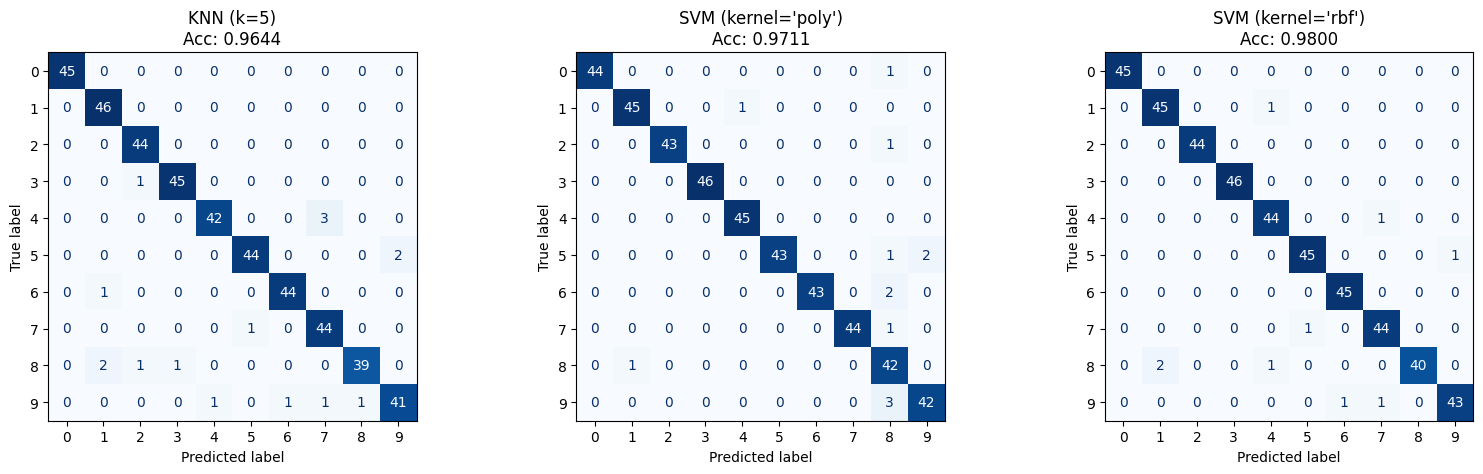

In [5]:
#btvn3
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# 1. Tải tập dữ liệu Digits từ sklearn.datasets
X, y = load_digits(return_X_y=True)

# 2. Phân chia tập huấn luyện và tập kiểm tra, rồi chuẩn hóa dữ liệu
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Huấn luyện lần lượt KNN, SVM (poly) và SVM (rbf)
models = {
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "SVM (kernel='poly')": SVC(kernel="poly", random_state=42),
    "SVM (kernel='rbf')": SVC(kernel="rbf", random_state=42),
}

results = {}

for name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    results[name] = (acc, cm)
    print(f"{name:22s} | Accuracy = {acc:.4f} ({acc * 100:.2f}%)")

# 4. Hiển thị ma trận nhầm lẫn (Confusion Matrix) của từng mô hình
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

for ax, (name, (acc, cm)) in zip(axes, results.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\nAcc: {acc:.4f}")

plt.tight_layout()
plt.show()